# Assignment 2: Diabetes Classification

**Workflow**

**UNDERSTAND → EDA → SPLIT → PREPARE → FIT → PREDICT → EVALUATE → INTERPRET**

The main idea throughout the notebook is:

**QUESTION → EVIDENCE → DECISION**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)


---
## Step 1 - Understand the data (Kristian)

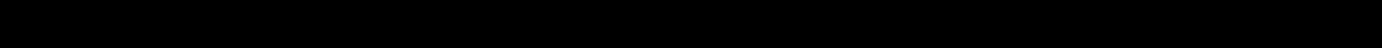


#### Q: Identify the input features X and the target y.

From `Diabetes_Understanding_the_Dataset.docx`, we know that the input X is the 21 features and the target y is `Diabetes_binary`, where 0 = no diabetes & 1 = prediabetes or diabetes.


#### Q: Explain what class 0 and class 1 mean.

As mentioned, class 0 means the respondent has no diabetes, and class 1 means they have _prediabetes_ or _diabetes_. We also see that _prediabetes_ and _diabetes_ both are in class 1, so we can't tell those apart ;(

#### Q: Check the number and proportion of observations in each class.

In [12]:
df = pd.read_csv("Data/diabetes.csv")
target = "Diabetes_binary"

X = df.drop(columns=target)
y = df[target]

print("Shape:", df.shape)
display(df.head())

Shape: (253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [21]:
print("Number of observations:")
display(df[target].value_counts()) # number
print("--------------------------")
print("Proportion of observations:")
display(df[target].value_counts(normalize=True)) # proportion

Number of observations:


Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

--------------------------
Proportion of observations:


Diabetes_binary
0.0    0.860667
1.0    0.139333
Name: proportion, dtype: float64

We see there are 218,334 respondents in class 0 (86.1 %) **don't have diabetes**, and 35,346 in class 1 (13.9 %) either **have _diabetes_ or _prediabetes_**

#### Q: Choose three features of different types and briefly explain what their values mean. Use the Understanding the Dataset guide.

From the dataset guide, section 3 "Complete feature guide", let's pick features `BMI`, `HighBP`, `Age`:

| Feature | Type | What the values mean                                               |
|:---|:---|:-------------------------------------------------------------------|
| `BMI` | Numerical | A measured value, so BMI = 30 is an actual BMI of 30               |
| `HighBP` | Binary | 0 = no and 1 = yes, respondent has high blood pressure             |
| `Age` | Ordinal | An age group, so Age = 9 means 60–64 years old and not 9 years old |

So a number in the CSV isn't always an amount, and we have to check what it means before we use it.

---
## Step 2 - Explore the data (Kristian)


#### For numerical features, examine their distributions and compare them between the two target classes.

The only numerical features listed in "3. Complete feature guide" are `BMI`, `MentHlth` & `PhysHlth`:

In [23]:
numerical_features = ["BMI", "MentHlth", "PhysHlth"]

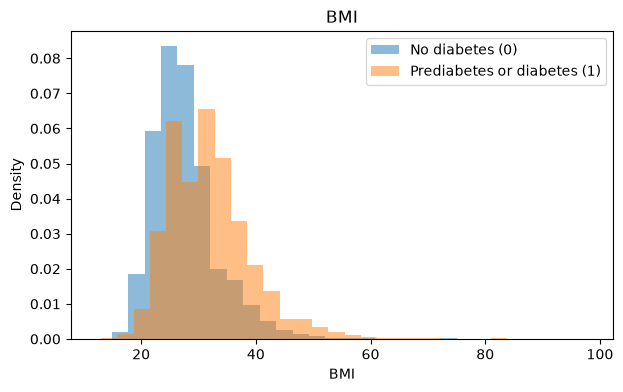

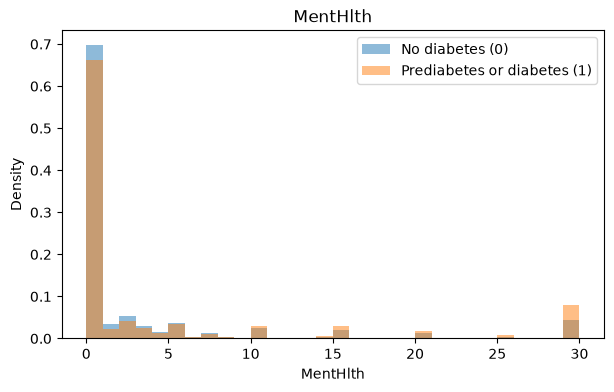

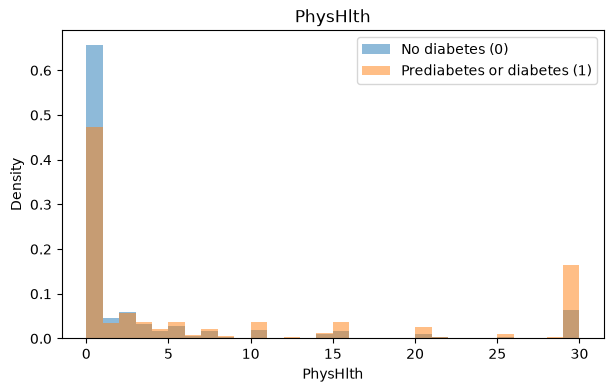

In [24]:
for feature in numerical_features:
    plt.figure(figsize=(7, 4))

    df.loc[df[target] == 0, feature].plot(
        kind="hist", bins=30, alpha=0.5, density=True, label="No diabetes (0)"
    )
    df.loc[df[target] == 1, feature].plot(
        kind="hist", bins=30, alpha=0.5, density=True, label="Prediabetes or diabetes (1)"
    )

    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.title(feature)
    plt.legend()
    plt.show()

**What do we see?**

- `BMI`: class 1 has a higher BMI.
- `MentHlth`: almost no difference.
- `PhysHlth`: class 1 more often has many days of poor physical health.

`BMI` & `PhysHlth` seem related to diabetes, `MentHlth` not so much. This is only an association, not cause and effect.

#### For binary categorical features, examine counts/proportions and compare the proportion of Diabetes_binary across the two categories.

#### For ordered categorical features, examine how the distribution or proportion of Diabetes_binary changes across the ordered categories.

#### Explore all input features, but focus your detailed interpretation on the most informative or interesting results. You may use loops or functions where appropriate rather than repeating essentially identical code.

#### For the results you discuss in detail, state the question, show appropriate evidence, explain what you observe, and explain what the evidence allows you to conclude and what it does not.

#### Look for patterns such as differences between the two target classes, changes in the proportion of class 1 across categories, unusual distributions, and features that appear to have little relationship with the target.

#### Remember: EDA describes associations and patterns in the observed data; an association does not show that one variable causes diabetes.

## Step 3 - Create TRAIN and TEST (Emilie)

#### Split X and y into TRAIN and TEST.

#### Use stratify=y so that TRAIN and TEST have approximately the same proportion of class 0 and class 1.

#### Keep TEST separate until evaluation. Do not balance or resample TEST.

## Step 4 - Prepare the features (Kristian)

#### Prepare the input features using the information in the Understanding the Dataset guide and the preprocessing methods introduced in the course. Your preprocessing choice should reflect whether a feature is numerical, binary categorical, or ordered categorical. Briefly justify how you represent each type.

#### There are no missing values in this dataset, so missing-value imputation is not required.

#### Use a Pipeline/ColumnTransformer where appropriate.

#### Anything learned from the data during preprocessing must be learned from TRAIN only and then applied to TEST.

## Step 5 - Train logicstic regression (David)

#### Use Logistic Regression, as introduced in the classification lecture. Fit the complete Pipeline using TRAIN.

#### Use model.predict(X_test) to obtain predicted classes.

#### Use model.predict_proba(X_test)[:, 1] to obtain predicted probabilities for class 1.

## Step 6 - Evaluate the model (David)

#### Evaluate the model on TEST: confusion matrix.

#### Evaluate the model on TEST: accuracy.

#### Evaluate the model on TEST: precision.

#### Evaluate the model on TEST: recall.

#### Evaluate the model on TEST: F1 score.

#### Explain what a false positive and a false negative mean for this diabetes classification problem. Do not judge the model from accuracy alone.

## Step 7 - Probability and threshold (Emilie)

#### Use the predicted probabilities from Logistic Regression to compare two decision thresholds: 0.50 and 0.40.

#### For each threshold, calculate the confusion matrix, precision and recall.

#### Compare the results. Explain what happened to false positives, false negatives, precision and recall.

#### Also explain what did NOT change when you changed only the threshold.

## Step 8 - Conclusion (Emilie)

#### Summarize the most important things you learned from the EDA and the Logistic Regression results.

#### Give at least two limitations of this analysis.

#### Do not interpret an association as evidence that one feature causes diabetes.